# 09 · MLOps Toolkit — *from scratch*

The earlier notebooks *built* a model. **MLOps** is everything that keeps it
running responsibly once it's live. This notebook implements each core piece in
plain Python — no project imports, no heavy frameworks — so you can see exactly
what each one *is*:

1. **Data validation** — a bouncer that rejects bad data.
2. **Hyperparameter tuning** — let the computer search for better settings.
3. **Experiment tracking** — a lab notebook of every run.
4. **Explainability** — which features drive the price?
5. **Model registry** — version models so you can roll back.
6. **Monitoring** — watch live predictions and error.
7. **Drift detection** — has new data drifted from training data?

Each real-world upgrade (pandera, Optuna, MLflow, SHAP, Evidently, …) is named as
we go, but everything here runs with just pandas / scikit-learn / scipy.

In [1]:
# --- Self-contained setup + a freshly trained pipeline to operate on --------
import warnings
warnings.filterwarnings("ignore")   # hide library deprecation notices for clean output

import json, time, hashlib, shutil
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

DATA_PATH     = "../data/raw/cars24-car-price-cleaned-new.csv.gz"
TARGET        = "selling_price"
TARGET_ENCODE = ["make", "model"]
NUMERIC       = ["km_driven", "mileage", "engine", "max_power", "age"]
FLAGS         = ["Individual", "Trustmark Dealer", "Diesel", "Electric", "LPG",
                 "Petrol", "Manual", "Seats_5", "Seats_Above_5"]
FEATURES      = TARGET_ENCODE + NUMERIC + FLAGS
TEST_SIZE, RANDOM_STATE = 0.2, 42
KPI = {"max_mae_lakhs": 1.0, "min_r2": 0.85, "min_band_accuracy": 0.70}

# Keep every artifact these demos create under one throwaway folder so we never
# touch the project's real models/ or experiments/ directories.
WORK = Path("../artifacts_basics"); WORK.mkdir(exist_ok=True)


def clean(df):
    df = df.rename(columns={"5": "Seats_5", ">5": "Seats_Above_5"})
    df = df.dropna(subset=[TARGET])
    df = df[df[TARGET] > 0].dropna()
    for c in TARGET_ENCODE:
        df[c] = df[c].astype(str).str.strip().str.upper()
    return df.reset_index(drop=True)


def build_preprocessor():
    return ColumnTransformer([
        ("target_enc", TargetEncoder(target_type="continuous", random_state=RANDOM_STATE), TARGET_ENCODE),
        ("passthrough", "passthrough", NUMERIC + FLAGS),
    ], remainder="drop")


def make_model():
    try:
        from lightgbm import LGBMRegressor
        return LGBMRegressor(n_estimators=600, num_leaves=63, learning_rate=0.05,
                             n_jobs=-1, random_state=RANDOM_STATE, verbosity=-1)
    except ImportError:
        from sklearn.ensemble import HistGradientBoostingRegressor
        return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06,
                                              max_depth=8, random_state=RANDOM_STATE)


df = clean(pd.read_csv(DATA_PATH))
X, y = df[FEATURES].copy(), df[TARGET].copy()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

pipe = Pipeline([("preprocess", build_preprocessor()), ("model", make_model())])
pipe.fit(Xtr, ytr)
print("ready: trained", type(pipe.named_steps["model"]).__name__, "on", len(Xtr), "rows")

ready: trained LGBMRegressor on 15856 rows


## 1 · Data validation — a bouncer for the data
Before training or serving, check the data looks the way we expect: required
columns present, prices positive, numbers within physically sane ranges. Fail
**loudly** instead of quietly learning from garbage. *(Heavy-duty upgrades:
**pandera**, **Great Expectations**.)*

In [2]:
# Physically-plausible bounds for each numeric column (wider than model limits;
# these only catch nonsense like a negative price or a 9000-bhp engine).
RANGES = {"selling_price": (0.01, 500.0), "age": (0, 60), "km_driven": (0, 1_000_000),
          "mileage": (0.0, 60.0), "engine": (0, 8000), "max_power": (0.0, 2000.0)}


def validate(df):
    """Return (ok, errors, warnings). Errors are hard failures; warnings are soft."""
    errors, warnings = [], []
    required = [TARGET] + TARGET_ENCODE + NUMERIC

    missing = [c for c in required if c not in df.columns]
    if missing:
        errors.append(f"missing required column(s): {missing}")

    for c in required:                                  # nulls -> warning
        if c in df.columns and df[c].isna().any():
            warnings.append(f"'{c}' has {int(df[c].isna().sum()):,} null(s)")

    for c, (lo, hi) in RANGES.items():                  # out-of-range -> warning
        if c in df.columns:
            s = pd.to_numeric(df[c], errors="coerce")
            n_bad = int(((s < lo) | (s > hi)).sum())
            if n_bad:
                warnings.append(f"'{c}' has {n_bad:,} value(s) outside [{lo}, {hi}]")

    if TARGET in df.columns and (pd.to_numeric(df[TARGET], errors="coerce") <= 0).any():
        errors.append(f"'{TARGET}' contains non-positive prices")     # hard failure

    return (len(errors) == 0), errors, warnings


ok, errors, warnings = validate(df)
print("clean data ->", "PASS" if ok else "FAIL", "| errors:", errors, "| warnings:", warnings)

# Show it CATCHING a problem: inject a negative price and a null.
bad = df.head(50).copy()
bad.loc[0, "selling_price"] = -5
bad.loc[1, "engine"] = np.nan
print("tampered data ->", validate(bad)[0], "|", validate(bad)[1], validate(bad)[2])

clean data -> PASS | errors: [] | warnings: ["'km_driven' has 3 value(s) outside [0, 1000000]", "'mileage' has 4 value(s) outside [0.0, 60.0]"]
tampered data -> False | ["'selling_price' contains non-positive prices"] ["'engine' has 1 null(s)", "'selling_price' has 1 value(s) outside [0.01, 500.0]"]


## 2 · Hyperparameter tuning — search for better settings
Same idea as nb 08's fine-tuning, applied here as a reusable step: sample random
settings, score each with cross-validation, keep the best — and (in section 3)
**log the result**. *(Smarter upgrade: **Optuna**, which learns which settings to
try next.)*

In [3]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import randint, uniform

# Tune whichever booster we trained. Params are addressed as 'model__<name>'
# because the estimator is the "model" step inside the Pipeline.
model_name = type(pipe.named_steps["model"]).__name__
if "LGBM" in model_name:
    space = {"model__n_estimators": randint(300, 900),
             "model__num_leaves": randint(15, 127),
             "model__learning_rate": uniform(0.01, 0.12)}
else:
    space = {"model__max_iter": randint(200, 600),
             "model__learning_rate": uniform(0.02, 0.15),
             "model__max_depth": randint(4, 12)}

search = RandomizedSearchCV(
    Pipeline([("preprocess", build_preprocessor()), ("model", make_model())]),
    space, n_iter=6, scoring="neg_mean_absolute_error",
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X, y)

best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
tune_result = {"model": model_name, "best_cv_mae_lakhs": round(float(-search.best_score_), 3),
               "best_params": best_params}
print("best CV MAE:", tune_result["best_cv_mae_lakhs"], "Lakhs")
tune_result["best_params"]

best CV MAE: 0.695 Lakhs


{'learning_rate': 0.01676938948325203, 'n_estimators': 643, 'num_leaves': 122}

## 3 · Experiment tracking — a lab notebook of runs
Every time you train or tune, jot down *what settings you used* and *how well it
did*, so later you can ask "which run was best, and what did it use?" We append
one JSON line per run to a file. *(Upgrade: **MLflow** — `mlflow ui` gives a
browsable dashboard.)*

In [4]:
RUNS = WORK / "runs.jsonl"


def log_run(run_name, params, metrics):
    """Append one experiment run (name + params + metrics + timestamp)."""
    record = {"run_name": run_name, "time": time.strftime("%Y-%m-%dT%H:%M:%S"),
              "params": params, "metrics": metrics}
    with open(RUNS, "a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
    return record


def load_runs():
    """Read every logged run back into a flat DataFrame."""
    if not RUNS.exists():
        return pd.DataFrame()
    rows = [json.loads(x) for x in RUNS.read_text().splitlines() if x]
    flat = []
    for r in rows:
        d = {"run_name": r["run_name"], "time": r["time"]}
        d.update({f"param.{k}": v for k, v in r["params"].items()})
        d.update({f"metric.{k}": v for k, v in r["metrics"].items()})
        flat.append(d)
    return pd.DataFrame(flat)


# Log the tuning run from section 2.
log_run(f"tune-{model_name}", tune_result["best_params"],
        {"cv_mae_lakhs": tune_result["best_cv_mae_lakhs"]})
load_runs().tail(3)

,run_name,time,param.learning_rate,param.n_estimators,param.num_leaves,metric.cv_mae_lakhs
0,tune-LGBMRegressor,2026-08-22T02:29:29,0.016769,643,122,0.695
1,tune-LGBMRegressor,2026-08-22T02:35:46,0.016769,643,122,0.695


## 4 · Explainability — which features drive the price?
A prediction is more trustworthy if the model can say *what mattered*. Two simple
views:
- **Built-in importances** — how often the model split on each feature.
- **Permutation importance** — shuffle one feature and measure how much worse the
  predictions get. Model-agnostic and more honest. *(Upgrade: **SHAP**, which
  explains individual predictions.)*

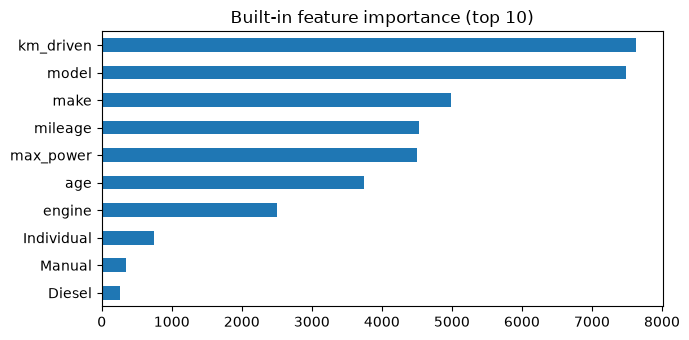

km_driven    7633
model        7490
make         4994
mileage      4537
max_power    4506
age          3739
dtype: int32

In [5]:
import matplotlib.pyplot as plt

model = pipe.named_steps["model"]
importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)

ax = importances.head(10)[::-1].plot.barh(figsize=(7, 3.5),
                                          title="Built-in feature importance (top 10)")
plt.tight_layout(); plt.show()
importances.head(6).round(3)

In [6]:
from sklearn.inspection import permutation_importance

# Shuffle each raw input column on the TEST set; the bigger the MAE increase,
# the more the model relies on that column.
perm = permutation_importance(pipe, Xte, yte, n_repeats=5,
                              random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error", n_jobs=1)
(pd.Series(perm.importances_mean, index=FEATURES)
   .sort_values(ascending=False).head(6).round(4))

age          1.0672
model        1.0556
max_power    0.8842
make         0.4534
engine       0.2842
km_driven    0.0787
dtype: float64

## 5 · Model registry — version every model so you can roll back
Like "Save As… v1, v2, v3" for models. Each `register()` copies the model file
into `registry/<version>/` with its metrics and a short content **hash**
(a fingerprint), and records it in an index. You can mark one version
"production" and roll back if a new one misbehaves. *(Upgrades: **MLflow Model
Registry**, **DVC**.)*

In [7]:
import joblib

REGISTRY = WORK / "registry"; REGISTRY.mkdir(exist_ok=True)
INDEX = REGISTRY / "index.json"

# Save the current pipeline once so the registry has something to copy.
current = WORK / "price_pipeline.pkl"
joblib.dump(pipe, current, compress=("lzma", 9))


def register(pipeline_path, metrics, note="", stage="staging"):
    """Copy a model file into the registry as a new immutable version."""
    entries = json.loads(INDEX.read_text()) if INDEX.exists() else []
    version = f"v{len(entries) + 1}-{time.strftime('%Y%m%d-%H%M%S')}"
    dest = REGISTRY / version; dest.mkdir(parents=True, exist_ok=True)
    shutil.copy2(pipeline_path, dest / "price_pipeline.pkl")

    fingerprint = hashlib.sha256(Path(pipeline_path).read_bytes()).hexdigest()[:12]
    entry = {"version": version, "hash": fingerprint,
             "time": time.strftime("%Y-%m-%dT%H:%M:%S"),
             "stage": stage, "note": note, "metrics": metrics}
    entries.append(entry)
    INDEX.write_text(json.dumps(entries, indent=2))
    return entry


entry = register(current, {"model": model_name, "cv_mae": tune_result["best_cv_mae_lakhs"]},
                 note="from notebook 09_basics")
print("registered:", entry["version"], "| hash:", entry["hash"], "| stage:", entry["stage"])
entry["metrics"]

registered: v2-20260822-023558 | hash: 40c120121858 | stage: staging


{'model': 'LGBMRegressor', 'cv_mae': 0.695}

## 6 · Monitoring — watch predictions and live error
Once live, log every prediction; when the *real* price arrives later, attach it
and compute the **live MAE**. If live error creeps above the KPI, that's your
signal to investigate or retrain. *(Upgrades: **Grafana**, **Evidently**.)*

In [8]:
PRED_LOG = WORK / "predictions.jsonl"


def log_prediction(inputs, predicted_lakhs, actual_lakhs=None):
    """Append one served prediction (and the true price, if known yet)."""
    rec = {"time": time.strftime("%Y-%m-%dT%H:%M:%S"), "inputs": inputs,
           "predicted_lakhs": round(float(predicted_lakhs), 2), "actual_lakhs": actual_lakhs}
    with open(PRED_LOG, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec) + "\n")
    return rec


def live_metrics():
    """MAE over logged predictions that have a known actual price."""
    rows = [json.loads(x) for x in PRED_LOG.read_text().splitlines() if x] if PRED_LOG.exists() else []
    labelled = [r for r in rows if r["actual_lakhs"] is not None]
    if not labelled:
        return {"n_predictions": len(rows), "n_with_actual": 0, "live_mae_lakhs": None}
    mae = float(np.mean([abs(r["predicted_lakhs"] - r["actual_lakhs"]) for r in labelled]))
    return {"n_predictions": len(rows), "n_with_actual": len(labelled),
            "live_mae_lakhs": round(mae, 3), "kpi_breached": mae > KPI["max_mae_lakhs"]}


# Simulate two live predictions whose true prices later came in.
for car, actual in [({"make": "MARUTI", "model": "SWIFT VXI"}, 5.5),
                    ({"make": "BMW", "model": "X5"}, 19.0)]:
    row = {c: 0 for c in FEATURES}
    row["make"], row["model"] = car["make"], car["model"]
    for c in NUMERIC:
        row[c] = float(df[c].median())
    p = float(pipe.predict(pd.DataFrame([row])[FEATURES])[0])
    log_prediction(car, p, actual_lakhs=actual)

live_metrics()

{'n_predictions': 4,
 'n_with_actual': 4,
 'live_mae_lakhs': 2.47,
 'kpi_breached': True}

## 7 · Drift detection — has new data drifted from training data?
A model learned from *last year's* cars. If *this year's* cars are systematically
different (older, higher mileage), predictions worsen even though the code never
changed. We measure that per feature two ways:
- **PSI** (Population Stability Index): how much a distribution moved.
  `<0.1` none · `0.1–0.2` moderate · `>0.2` significant.
- **KS test** (scipy): "are these two samples statistically different?"

*(Richer upgrade: **Evidently** drift reports.)*

In [9]:
from scipy.stats import ks_2samp


def psi(expected, actual, bins=10):
    """Population Stability Index between two 1-D samples."""
    expected, actual = np.asarray(expected, float), np.asarray(actual, float)
    edges = np.quantile(expected, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


def detect_drift(reference, current, features=NUMERIC, psi_threshold=0.2):
    """Per-feature PSI + KS p-value + a drift flag; plus an overall summary."""
    rows = []
    for c in features:
        ref = pd.to_numeric(reference[c], errors="coerce").dropna().values
        cur = pd.to_numeric(current[c], errors="coerce").dropna().values
        p = psi(ref, cur)
        ks_p = float(ks_2samp(ref, cur).pvalue)
        rows.append({"feature": c, "psi": round(p, 3), "ks_pvalue": round(ks_p, 4),
                     "drift": bool(p > psi_threshold or ks_p < 0.05)})
    report = pd.DataFrame(rows)
    return {"drift_detected": bool(report["drift"].any()),
            "n_drifted": int(report["drift"].sum()), "report": report}


# Simulate drift: pretend this year's cars are 8 years older than the reference.
ref = df.sample(frac=0.5, random_state=1)
cur = df.sample(frac=0.5, random_state=2).copy()
cur["age"] = cur["age"] + 8

out = detect_drift(ref, cur)
print("drift detected:", out["drift_detected"], "| features drifted:", out["n_drifted"])
out["report"]

drift detected: True | features drifted: 1


,feature,psi,ks_pvalue,drift
0,km_driven,0.001,0.9327,False
1,mileage,0.001,0.9947,False
2,engine,0.001,0.5284,False
3,max_power,0.002,0.7411,False
4,age,10.055,0.0000,True


## The whole loop
**validate → tune/train → track → explain → register → serve → monitor → drift? →
retrain**. Each box above is a small, understandable function; production tools
(pandera, Optuna, MLflow, SHAP, Evidently, DVC) are just sturdier versions of
these same ideas.

> Everything this notebook created lives under `../artifacts_basics/` — safe to
> delete; it never touches the project's real `models/` or `experiments/`.